# Phase 3c — 다른 모델들을 새 피처로 재검증

03b에서 만든 피처 세트 **D = V1~V28 + log 금액 + 시간대(sin, cos) + 평면 이탈 거리 (32개)**로,
Phase 3에서 부진했던 모델들을 다시 검증합니다.

| 모델 | Phase 3 결과 (원본 피처, PR-AUC) | 이번에 확인할 것 |
|---|---|---|
| LOF | 0.002 (사실상 실패) | 새 피처로 살아나는가 |
| One-Class SVM | 0.105 | 새 피처로 얼마나 나아지는가 |
| **kNN 거리** (새로 추가) | - | LOF와 같은 이웃을 쓰지만 "전역적 거리"를 봄 → "LOF가 실패한 건 국소(local) 방식이라서"라는 가설 검증 |

비교 기준: 평면 이탈 거리 단독 (리더보드 Public 0.8294 / Private 0.8306), 마할라노비스 D, IF D

평가는 두 갈래로 합니다.
1. **전체 성능**: 최적 macro-F1, contamination macro-F1, PR-AUC
2. **평면 위 / 평면 밖 부분집합별 성능**: 거리 단독이 원리상 못 잡는 "평면 위 사기"를 어떤 모델이 잡을 수 있는지,
   평면 밖에서는 거리보다 더 잘 가려내는 모델이 있는지 확인합니다.

(먼저 03b 노트북의 섹션 12 셀을 실행해서 피처 파일을 만들어 두어야 합니다.)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 03b에서 저장한 피처 불러오기
train_fe = pd.read_pickle('../data/train_fe.pkl')
val_fe = pd.read_pickle('../data/val_fe.pkl')
test_fe = pd.read_pickle('../data/test_fe.pkl')
y_true = val_fe['Class'].values

# 피처 세트 D (32개)
cols_D = [f'V{i}' for i in range(1, 29)] + ['log_amount', 'hour_sin', 'hour_cos', 'off_plane_dist']

# 거리·밀도 기반 모델용 스케일링 (train 기준으로 평균 0, 표준편차 1)
scaler = StandardScaler().fit(train_fe[cols_D])
X_tr = scaler.transform(train_fe[cols_D])
X_va = scaler.transform(val_fe[cols_D])

# 평면 위/밖 구분 (평면 이탈 거리가 사실상 0이면 평면 위)
on_plane_val = val_fe['off_plane_dist'].values < 1e-6

print('train:', X_tr.shape, '/ val:', X_va.shape)
print(f'val 평면 위: 정상 {(on_plane_val & (y_true == 0)).sum()}건, 사기 {(on_plane_val & (y_true == 1)).sum()}건')
print(f'val 평면 밖: 정상 {(~on_plane_val & (y_true == 0)).sum()}건, 사기 {(~on_plane_val & (y_true == 1)).sum()}건')

train: (113842, 32) / val: (28462, 32)
val 평면 위: 정상 25111건, 사기 5건
val 평면 밖: 정상 3321건, 사기 25건


## 공통 함수

03b와 같은 채점 함수입니다. contamination threshold를 쓰려면 **train 점수**도 필요해서, 모델마다 (train 점수, val 점수)를 같이 만들어 둡니다.

In [2]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def find_best_threshold(y_true, scores, max_k=2000):
    # 점수 상위 k건을 사기로 예측하는 모든 경우(k=1~max_k)를 빠짐없이 탐색
    order = np.argsort(-scores)
    sorted_y = y_true[order]
    n_pos = y_true.sum()
    n_neg = len(y_true) - n_pos
    k = np.arange(1, max_k + 1)
    tp = np.cumsum(sorted_y)[:max_k]
    fp = k - tp
    fn = n_pos - tp
    tn = n_neg - fp
    macro = (2 * tp / (2 * tp + fp + fn) + 2 * tn / (2 * tn + fn + fp)) / 2
    best_idx = np.argmax(macro)
    return scores[order][best_idx], macro[best_idx]

val_contamination = (y_true == 1).sum() / (y_true == 0).sum()   # 약 0.1055%

def evaluate(name, train_scores, val_scores):
    # 점수(높을수록 사기)를 세 가지 방식으로 채점
    _, best_f1 = find_best_threshold(y_true, val_scores)
    threshold = np.quantile(train_scores, 1 - val_contamination)   # val 정답을 안 보는 threshold
    pred = (val_scores >= threshold).astype(int)
    return {
        '모델': name,
        '최적 macro-F1': round(float(best_f1), 4),
        'contamination macro-F1': round(float(f1_score(y_true, pred, average='macro')), 4),
        'contamination 예측 건수': int(pred.sum()),
        'PR-AUC': round(float(average_precision_score(y_true, val_scores)), 4),
        'ROC-AUC': round(float(roc_auc_score(y_true, val_scores)), 4),
    }

scores = {}   # 모델 이름 -> (train 점수, val 점수)

## 1. 비교 기준 점수: 평면 이탈 거리, 마할라노비스 D, IF D

03b에서 계산했던 것과 같은 점수를 여기서 다시 만듭니다 (IF는 1분 정도 걸립니다).
마할라노비스는 공분산으로 스스로 스케일을 맞추고, IF는 나무 기반이라 스케일링이 필요 없어서 원래 피처 값을 그대로 씁니다.

In [3]:
from sklearn.ensemble import IsolationForest

scores['평면 이탈 거리 단독'] = (train_fe['off_plane_dist'].values, val_fe['off_plane_dist'].values)

def mahalanobis_scores(X_fit, X_score):
    mu = X_fit.mean(axis=0)
    cov_inv = np.linalg.inv(np.cov(X_fit, rowvar=False))
    d = X_score - mu
    return np.sqrt(np.sum((d @ cov_inv) * d, axis=1))

raw_tr, raw_va = train_fe[cols_D].values, val_fe[cols_D].values
scores['마할라노비스 D'] = (mahalanobis_scores(raw_tr, raw_tr), mahalanobis_scores(raw_tr, raw_va))

iso = IsolationForest(n_estimators=125, max_samples=len(raw_tr), random_state=42, n_jobs=-1).fit(raw_tr)
scores['IF D'] = (-iso.score_samples(raw_tr), -iso.score_samples(raw_va))
print('완료')

완료


## 2. LOF (국소 밀도) vs kNN 거리 (전역 거리)

둘 다 "가장 가까운 이웃 20개"를 찾는 건 같지만, 점수를 매기는 관점이 다릅니다.
- **LOF**: 내 주변 밀도를 **이웃들의 주변 밀도와 비교**. 이웃들보다 내가 듬성하면 이상치 (상대적, 국소적)
- **kNN 거리**: 이웃 20개까지의 **평균 거리 그 자체**. 정상 거래들로부터 멀리 떨어져 있으면 이상치 (절대적, 전역적)

주의할 점: train 자기 자신을 점수 매길 때는 "자기 자신이 가장 가까운 이웃"으로 잡히면 안 됩니다.
- LOF: 학습 때 이미 자기 자신을 뺀 점수가 `negative_outlier_factor_`에 저장돼 있어서 그걸 씁니다.
- kNN: `kneighbors()`를 X 없이 부르면 자기 자신을 이웃에서 빼고 찾아줍니다.

각각 1~3분 정도 걸립니다.

In [4]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1).fit(X_tr)
scores['LOF D'] = (-lof.negative_outlier_factor_,    # train: 자기 자신을 뺀 LOF 점수
                   -lof.score_samples(X_va))          # val: 새 데이터 점수
print('LOF 완료')

LOF 완료


In [5]:
from sklearn.neighbors import NearestNeighbors

k = 20
nn = NearestNeighbors(n_neighbors=k, n_jobs=-1).fit(X_tr)
dist_tr_knn, _ = nn.kneighbors()        # X 없이 부르면 train 각 점에 대해 '자기 자신 제외' 이웃 20개
dist_va_knn, _ = nn.kneighbors(X_va)    # val 각 점에 대해 train 중 가장 가까운 20개
scores['kNN 거리 D'] = (dist_tr_knn.mean(axis=1), dist_va_knn.mean(axis=1))
print('kNN 완료')

kNN 완료


## 3. One-Class SVM

Phase 3와 같은 설정(RBF 커널, nu=0.01)입니다. train 11만 건 전체로 학습해서 **수 분에서 십수 분** 걸릴 수 있습니다.
너무 오래 걸리면 커널을 중단(Interrupt)하고 알려주세요. train 일부만 샘플링하는 방식으로 바꾸겠습니다.

In [6]:
from sklearn.svm import OneClassSVM

ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale').fit(X_tr)
scores['One-Class SVM D'] = (-ocsvm.decision_function(X_tr), -ocsvm.decision_function(X_va))
print('One-Class SVM 완료')

One-Class SVM 완료


## 4. 전체 성능 비교

In [7]:
overall = pd.DataFrame([evaluate(name, s_tr, s_va) for name, (s_tr, s_va) in scores.items()])
display(overall.sort_values('PR-AUC', ascending=False).reset_index(drop=True))

,모델,최적 macro-F1,contamination macro-F1,contamination 예측 건수,PR-AUC,ROC-AUC
0,평면 이탈 거리 단독,0.8332,0.7907,25,0.6773,0.9250
1,IF D,0.7498,0.7255,32,0.4831,0.9605
2,마할라노비스 D,0.7798,0.7341,34,0.4608,0.9595
3,kNN 거리 D,0.6562,0.5685,28,0.1993,0.9626
4,One-Class SVM D,0.6181,0.6073,81,0.1180,0.9342
5,LOF D,0.5078,0.4995,30,0.0021,0.5179


## 5. 평면 위 / 평면 밖 부분집합별 성능

val을 평면 위(사기 5건)와 평면 밖(사기 25건)으로 나눠서, 각 부분집합 **안에서** 사기를 얼마나 위로 올리는지(PR-AUC) 봅니다.

PR-AUC는 사기 비율에 따라 기본값이 달라서 부분집합끼리 직접 비교하기 어렵습니다. 그래서 **"무작위로 찍었을 때 대비 몇 배"**
(PR-AUC ÷ 사기 비율)도 같이 봅니다. 1배면 무작위와 같고, 클수록 좋습니다.
- 평면 위: 거리 단독은 모든 점수가 0으로 같아서 무작위(1배)일 수밖에 없습니다. 여기서 1배보다 확실히 높은 모델이 있으면
  "평면 위 사기"를 잡을 후보입니다. 단, 사기가 5건뿐이라 매우 불안정한 추정입니다.
- 평면 밖: 거리 단독보다 높은 모델이 있으면, 평면 밖 사기를 더 잘 가려내는 후보입니다.

In [8]:
rows = []
for subset_name, mask in [('평면 위', on_plane_val), ('평면 밖', ~on_plane_val)]:
    y_sub = y_true[mask]
    base_rate = y_sub.mean()   # 이 부분집합의 사기 비율 = 무작위로 찍었을 때의 PR-AUC
    for name, (_, s_va) in scores.items():
        pr_auc = average_precision_score(y_sub, s_va[mask])
        rows.append({'부분집합': subset_name, '모델': name, 'PR-AUC': round(float(pr_auc), 4),
                     '무작위 대비 배수': round(float(pr_auc / base_rate), 1)})

subset_results = pd.DataFrame(rows)
display(subset_results.pivot(index='모델', columns='부분집합', values=['PR-AUC', '무작위 대비 배수']))

PR-AUC         무작위 대비 배수      
부분집합               평면 밖    평면 위      평면 밖  평면 위
모델                                             
IF D             0.6388  0.0057      85.5  28.4
LOF D            0.0070  0.0016       0.9   8.1
One-Class SVM D  0.2282  0.0014      30.5   6.8
kNN 거리 D         0.3850  0.0014      51.5   7.1
마할라노비스 D         0.6738  0.0019      90.2   9.5
평면 이탈 거리 단독      0.8123  0.0003     108.7   1.5

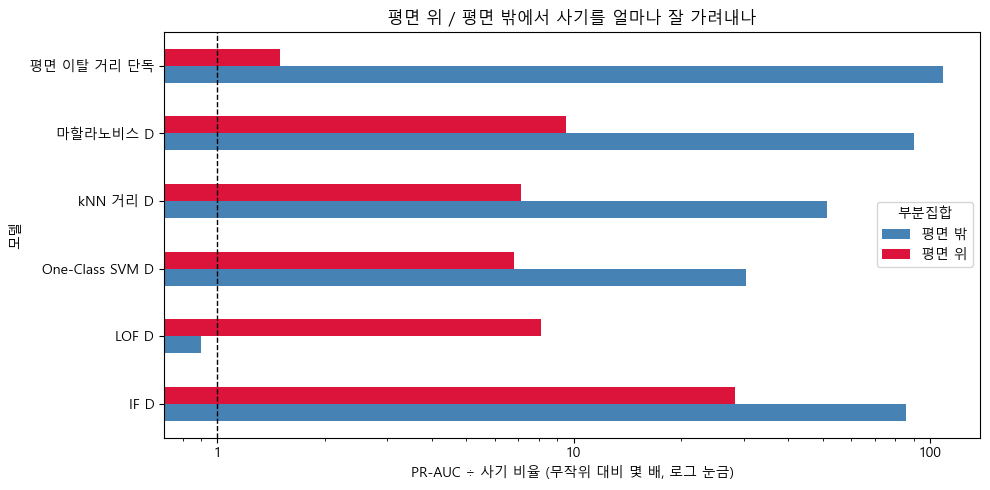

In [9]:
# 무작위 대비 배수를 부분집합별로 나란히 (로그 눈금: 1배 = 무작위)
pivot = subset_results.pivot(index='모델', columns='부분집합', values='무작위 대비 배수')
ax = pivot.plot(kind='barh', figsize=(10, 5), color=['steelblue', 'crimson'])
ax.set_xscale('log')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
ax.axvline(1, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('PR-AUC ÷ 사기 비율 (무작위 대비 몇 배, 로그 눈금)')
ax.set_title('평면 위 / 평면 밖에서 사기를 얼마나 잘 가려내나')
plt.tight_layout()
plt.show()

## 6. Phase 3c 요약

**전체 성능 (val, 피처 세트 D)**

| 모델 | contamination macro-F1 (예측 건수) | PR-AUC | ROC-AUC |
|---|---|---|---|
| **평면 이탈 거리 단독** | **0.7907** (25) | **0.6773** | 0.9250 |
| IF D | 0.7255 (32) | 0.4831 | 0.9605 |
| 마할라노비스 D | 0.7341 (34) | 0.4608 | 0.9595 |
| kNN 거리 D | 0.5685 (28) | 0.1993 | 0.9626 |
| One-Class SVM D | 0.6073 (81) | 0.1180 | 0.9342 |
| LOF D | 0.4995 (30) | 0.0021 | 0.5179 |

**부분집합별 (PR-AUC ÷ 사기 비율 = 무작위 대비 몇 배)**

| 모델 | 평면 밖 (사기 25건) | 평면 위 (사기 5건) |
|---|---|---|
| 평면 이탈 거리 단독 | **108.7배** | 1.5배 (사실상 무작위) |
| 마할라노비스 D | 90.2배 | 9.5배 |
| IF D | 85.5배 | **28.4배** |
| kNN 거리 D | 51.5배 | 7.1배 |
| One-Class SVM D | 30.5배 | 6.8배 |
| LOF D | 0.9배 | 8.1배 |

**결론**
1. **새 피처를 줘도 어떤 모델도 평면 이탈 거리 단독을 넘지 못함.** 평면 밖에서도 거리 단독이 최선.
2. **LOF는 새 피처로도 실패 (ROC-AUC 0.52).** 같은 이웃 20개를 쓰는 kNN 거리는 PR-AUC 0.20(LOF의 약 100배)이라,
   "이웃을 쓰는 것"이 아니라 **"이웃들과 상대적으로 비교하는 국소 방식"이 실패 원인**이라는 가설이 지지됨.
   평면 밖에서 LOF가 무작위(0.9배)인 것도 같은 맥락: 평면 밖 거래는 정상이든 사기든 비슷하게 듬성해서 상대 비교로는 구분 안 됨.
3. **ROC-AUC는 또 속였음**: kNN이 ROC-AUC 1등(0.963)인데 PR-AUC는 0.20.
4. **One-Class SVM의 contamination threshold가 망가짐 (val에서 81건 예측).** 학습한 train 자체에는 점수를 후하게 줘서
   train 기준 threshold가 val에서 너무 낮아짐. "train 점수로 threshold 정하기"는 모델이 train을 외우지 않는다는 전제가 필요함
   (kNN·LOF는 자기 자신을 이웃에서 빼서 이 문제를 피함).
5. **평면 위 사기는 현재 피처 + 비지도 모델로는 실제로 쓸 수 있는 수준으로 못 잡음.** IF D가 무작위의 28배지만 PR-AUC는 0.0057이고,
   5건 모두 상위 0.1%에 들지 못함 (IF D 백분위 0.53~0.996). 억지로 잡으려면 평면 위 정상 수백~수천 건을 같이 찍게 됨.
   → **현재 방식의 재현율 상한은 약 83%.** 5건 기준이라 불안정한 추정이고, 이 사기들은 정상과 사실상 구분이 안 되는 사기일 수 있음.

**다음 단계 (Phase 4)**: 오토인코더가 평면을 스스로 찾아내는지, 거리 단독을 넘거나 보완하는지 확인.